## 2107540 Data Science for Environmental and Sustainability
## Lecture 8 : Data Preparation with Python
### Done by : 6730084521 Chatrphol Ovanonchai

## Step 1 — Importing and Inspecting the Dataset 

### 1.1 Import the CSV file

In [84]:
import numpy as np
import pandas as pd
df = pd.read_csv("./river_water_quality.csv")
df.head()

,Timestamp,Conductivity,NO3,Temp,Turbidity,Dayofweek,Month
0,2017-05-11T14:00:00,13502.10,NaN,NaN,12.79,3,5
1,2017-05-11T15:00:00,10304.00,NaN,NaN,11.93,3,5
2,2017-05-11T16:00:00,5588.08,NaN,NaN,10.34,3,5
3,2017-05-11T17:00:00,13937.00,NaN,NaN,24.02,3,5
4,2017-05-11T18:00:00,44761.40,NaN,NaN,18.46,3,5


### 1.2 Inspect the dataset

In [85]:
print("Dataset shape:", df.shape)
print("\nColumn names:")

print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()

print("\nDescriptive statistics:")
display(df.describe())

Dataset shape: (25354, 7)

Column names:
['Timestamp', 'Conductivity', 'NO3', 'Temp', 'Turbidity', 'Dayofweek', 'Month']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 25354 entries, 0 to 25353
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Timestamp     25354 non-null  str    
 1   Conductivity  16037 non-null  float64
 2   NO3           6651 non-null   float64
 3   Temp          9816 non-null   float64
 4   Turbidity     16037 non-null  float64
 5   Dayofweek     25354 non-null  int64  
 6   Month         25354 non-null  int64  
dtypes: float64(4), int64(2), str(1)
memory usage: 1.8 MB

Descriptive statistics:


,Conductivity,NO3,Temp,Turbidity,Dayofweek,Month
count,16037.000000,6651.000000,9816.000000,16037.000000,25354.000000,25354.000000
mean,29702.847511,0.153235,26.544355,9.887324,3.000000,6.606374
std,18449.875493,0.242950,2.917798,28.281850,2.000592,3.483787
min,3.180000,0.001000,18.710000,-0.200000,0.000000,1.000000
25%,12741.900000,0.041000,24.450000,3.350000,1.000000,3.000000
50%,31262.070000,0.064000,26.697500,5.480000,3.000000,7.000000
75%,48147.000000,0.159000,28.980000,9.850000,5.000000,10.000000
max,57444.300000,1.552000,32.860000,2182.520000,6.000000,12.000000


### 1.3 Check the time coverage

In [86]:
print("First timestamp:", df["Timestamp"].min())
print("Last timestamp:", df["Timestamp"].max())

First timestamp: 2017-05-11T14:00:00
Last timestamp: 2020-04-01T23:00:00


## Step 2 — Data Quality Assessment

### 2.1 Identify missing values

In [87]:
missing_count = df.isna().sum()
missing_percent = df.isna().mean() * 100

missing_summary = pd.DataFrame({ 
                                "Missing_Count" : missing_count , 
                                "Missing_Percent" : missing_percent
                                })

display(
    missing_summary.sort_values("Missing_Percent" , ascending = [False]).round(2)
)

,Missing_Count,Missing_Percent
NO3,18703,73.77
Temp,15538,61.28
Conductivity,9317,36.75
Turbidity,9317,36.75
Timestamp,0,0.00
Dayofweek,0,0.00
Month,0,0.00


### 2.2 Visualize missingness

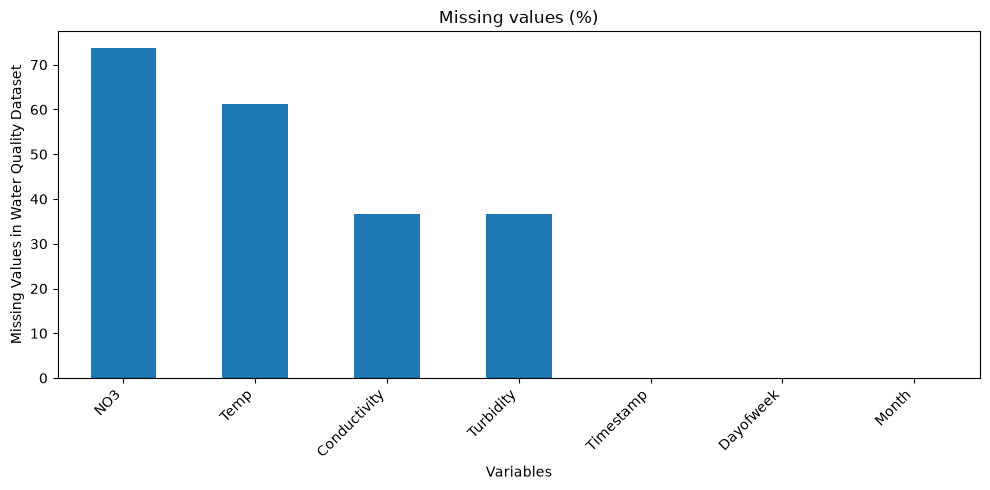

In [88]:
import matplotlib.pyplot as plt 

missing_percent = (df.isna().mean() * 100).sort_values(ascending = False)
missing_percent.plot(kind = "bar" , figsize=(10,5)) 

## decorate graph 
plt.title("Missing values (%)") 
plt.xlabel("Variables") 
plt.ylabel("Missing Values in Water Quality Dataset") 

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

### 2.3 Check duplicate records

In [89]:
print("Exact duplicate rows:", df.duplicated().sum())
duplicates = df[df.duplicated(keep=False)]
display(duplicates.head(10))

Exact duplicate rows: 0


,Timestamp,Conductivity,NO3,Temp,Turbidity,Dayofweek,Month


In [90]:
print(
 "Repeated timestamps:",
 df["Timestamp"].duplicated().sum()
)

Repeated timestamps: 0


## Step 3 — Data Cleaning and Transformation

### 3.1 Standardize column names

In [91]:
df_clean = df.copy()

## regex 
df_clean.columns = (
 df_clean.columns
 .str.strip()
 .str.lower()
 .str.replace(r"[^a-z0-9]+", "_", regex=True)
 .str.strip("_")
)

print(df_clean.columns.tolist())

['timestamp', 'conductivity', 'no3', 'temp', 'turbidity', 'dayofweek', 'month']


### 3.2 Convert the timestamp

In [92]:
print(df.columns)

print(df_clean.columns)

Index(['Timestamp', 'Conductivity', 'NO3', 'Temp', 'Turbidity', 'Dayofweek',
       'Month'],
      dtype='str')
Index(['timestamp', 'conductivity', 'no3', 'temp', 'turbidity', 'dayofweek',
       'month'],
      dtype='str')


In [93]:
df_clean["timestamp"] = pd.to_datetime(
 df_clean["timestamp"],
 errors="coerce"
)

print(df_clean["timestamp"].dtype)

print(
 "Invalid timestamps:",
 df_clean["timestamp"].isna().sum()
)

datetime64[us]
Invalid timestamps: 0


### 3.3 Validate the existing time features

In [94]:
df_clean["calculated_dayofweek"] = (
 df_clean["timestamp"].dt.dayofweek
)

df_clean["calculated_month"] = (
 df_clean["timestamp"].dt.month
)

day_mismatch = (
 df_clean["dayofweek"] != df_clean["calculated_dayofweek"]
)

month_mismatch = (
 df_clean["month"]
 != df_clean["calculated_month"]
)
print("Day-of-week mismatches:",day_mismatch.sum())
print("Month mismatches:", month_mismatch.sum())

Day-of-week mismatches: 0
Month mismatches: 0


### 3.4 Investigate suspicious numerical values

In [95]:
display(
 df_clean[
 ["conductivity", "no3", "temp", "turbidity"]
 ].describe()
)

,conductivity,no3,temp,turbidity
count,16037.000000,6651.000000,9816.000000,16037.000000
mean,29702.847511,0.153235,26.544355,9.887324
std,18449.875493,0.242950,2.917798,28.281850
min,3.180000,0.001000,18.710000,-0.200000
25%,12741.900000,0.041000,24.450000,3.350000
50%,31262.070000,0.064000,26.697500,5.480000
75%,48147.000000,0.159000,28.980000,9.850000
max,57444.300000,1.552000,32.860000,2182.520000


In [96]:
negative_turbidity = df_clean[
 df_clean["turbidity"] < 0
]
display(negative_turbidity)

,timestamp,conductivity,no3,temp,turbidity,dayofweek,month,calculated_dayofweek,calculated_month
6324,2018-01-30 02:00:00,20.81,NaN,NaN,-0.18,1,1,1,1
6374,2018-02-01 04:00:00,41.00,NaN,NaN,-0.09,3,2,3,2
6398,2018-02-02 04:00:00,60.06,NaN,NaN,-0.20,4,2,4,2
7020,2018-02-28 02:00:00,74.45,NaN,NaN,-0.18,2,2,2,2
7070,2018-03-02 04:00:00,52.76,NaN,NaN,-0.16,4,3,4,3


## Step 4 — Handling Missing Values

### 4.1 Compare three approaches

In [97]:
conductivity_original = df_clean["conductivity"]
print("Available observations:", conductivity_original.notna().sum())
print("Missing observations:", conductivity_original.isna().sum())

## drop na to new dataframe
df_conductivity_dropna = df_clean.dropna(subset=["conductivity"])

print("Rows before:", len(df_clean))
print("Rows after:", len(df_conductivity_dropna))

Available observations: 16037
Missing observations: 9317
Rows before: 25354
Rows after: 16037


### 4.2 Compare the consequences 

In [98]:
## define median value 
df_conductivity_median = df_clean.copy()
median_conductivity = (
 df_conductivity_median["conductivity"].median()
)

## mean data imputation
df_conductivity_median["conductivity"] = (
 df_conductivity_median["conductivity"]
 .fillna(median_conductivity)
)

## check NA
print(
 df_conductivity_median["conductivity"].isna().sum()
)

0


In [99]:
comparison = pd.DataFrame({
 "Original": df_clean["conductivity"].describe(),
 "Drop missing": df_conductivity_dropna["conductivity"].describe(),
 "Median imputed": df_conductivity_median["conductivity"].describe()
})
display(comparison)

,Original,Drop missing,Median imputed
count,16037.000000,16037.000000,25354.000000
mean,29702.847511,29702.847511,30275.825184
std,18449.875493,18449.875493,14692.509942
min,3.180000,3.180000,3.180000
25%,12741.900000,12741.900000,23752.975000
50%,31262.070000,31262.070000,31262.070000
75%,48147.000000,48147.000000,39102.510250
max,57444.300000,57444.300000,57444.300000


## Step 5 — Time-Series Transformation and Summary

### 5.1 Sort the observations chronologically 

In [100]:
df_clean = df_clean.sort_values("timestamp").reset_index(drop=True)
display(df_clean.head())

,timestamp,conductivity,no3,temp,turbidity,dayofweek,month,calculated_dayofweek,calculated_month
0,2017-05-11 14:00:00,13502.10,NaN,NaN,12.79,3,5,3,5
1,2017-05-11 15:00:00,10304.00,NaN,NaN,11.93,3,5,3,5
2,2017-05-11 16:00:00,5588.08,NaN,NaN,10.34,3,5,3,5
3,2017-05-11 17:00:00,13937.00,NaN,NaN,24.02,3,5,3,5
4,2017-05-11 18:00:00,44761.40,NaN,NaN,18.46,3,5,3,5


### 5.2 Create time features

In [101]:
df_clean["year"] = df_clean["timestamp"].dt.year
df_clean["month"] = df_clean["timestamp"].dt.month
df_clean["day"] = df_clean["timestamp"].dt.day
df_clean["hour"] = df_clean["timestamp"].dt.hour

display(
 df_clean[
 ["timestamp", "year", "month", "day", "hour"]
 ].head()
)

,timestamp,year,month,day,hour
0,2017-05-11 14:00:00,2017,5,11,14
1,2017-05-11 15:00:00,2017,5,11,15
2,2017-05-11 16:00:00,2017,5,11,16
3,2017-05-11 17:00:00,2017,5,11,17
4,2017-05-11 18:00:00,2017,5,11,18


### 5.3 Summarize monthly conductivity

In [102]:
## group by then aggregate value 
## then create dataframe
monthly_summary = (
 df_clean
 .groupby(["year", "month"])["conductivity"]
 .agg(["count", "mean", "median", "min", "max"])
 .reset_index()
)
display(monthly_summary.head(12))

,year,month,count,mean,median,min,max
0,2017,5,490,29494.021816,26855.70,3129.75,51365.4
1,2017,6,541,33654.087782,33868.50,7090.02,52055.8
2,2017,7,505,30436.934317,28775.00,24.72,52706.4
3,2017,8,497,35637.910584,36894.60,79.13,53843.8
4,2017,9,377,38401.900371,41282.10,117.48,57429.4
5,2017,10,470,35918.656021,37661.45,147.14,57444.3
6,2017,11,360,34643.785083,35044.70,184.61,57142.7
7,2017,12,372,38597.634113,40582.05,73.49,53233.2
8,2018,1,371,28876.991671,30968.50,20.81,53554.5
9,2018,2,335,17810.453940,10272.50,41.00,53487.3


### 5.4 Plot monthly conductivity

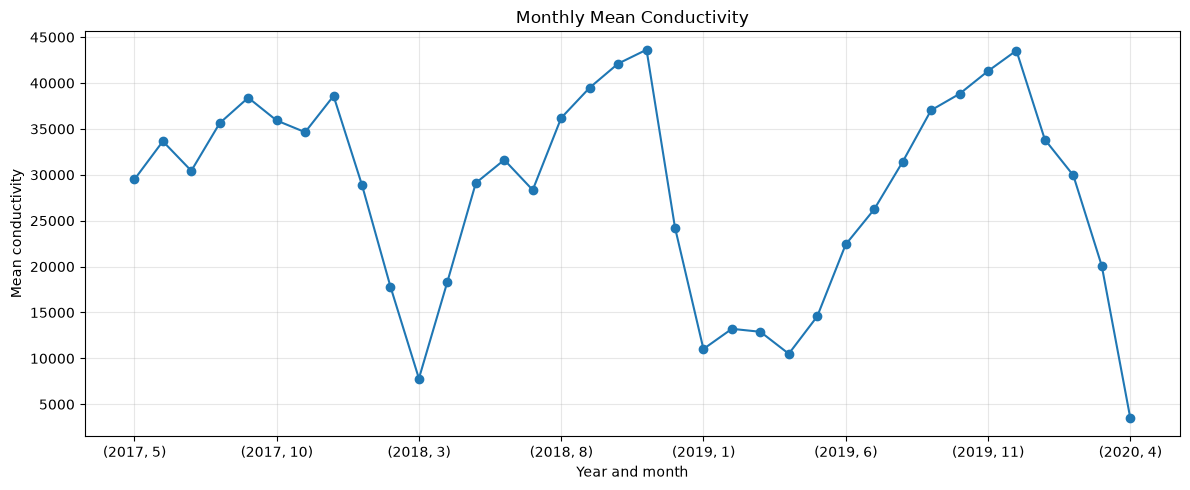

In [103]:
## groupby then aggregate
monthly_mean = (
 df_clean
 .groupby(["year", "month"])["conductivity"]
 .mean()
)

monthly_mean.plot(
 figsize=(12, 5),
 marker="o"
)

plt.xlabel("Year and month")
plt.ylabel("Mean conductivity")
plt.title("Monthly Mean Conductivity")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Step 6 — Validation and Export

### 6.1 Validate the processed dataset

In [104]:
print("Final shape:", df_clean.shape)
print("\nData types:")
print(df_clean.dtypes)
print("\nMissing values:")
print(df_clean.isna().sum())
print("\nExact duplicate rows:", df_clean.duplicated().sum())
print(
 "\nTimestamp range:",
 df_clean["timestamp"].min(),
 "to",
 df_clean["timestamp"].max()
)

Final shape: (25354, 12)

Data types:
timestamp               datetime64[us]
conductivity                   float64
no3                            float64
temp                           float64
turbidity                      float64
dayofweek                        int64
month                            int32
calculated_dayofweek             int32
calculated_month                 int32
year                             int32
day                              int32
hour                             int32
dtype: object

Missing values:
timestamp                   0
conductivity             9317
no3                     18703
temp                    15538
turbidity                9317
dayofweek                   0
month                       0
calculated_dayofweek        0
calculated_month            0
year                        0
day                         0
hour                        0
dtype: int64

Exact duplicate rows: 0

Timestamp range: 2017-05-11 14:00:00 to 2020-04-01 23:00:00


### 6.2 Export the processed data 

In [105]:
output_filename = "water_quality_processed.csv"
df_clean.to_csv(
 output_filename,
 index=False
)